In [1]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
iris = load_iris()
x = iris.data
feature_names = iris.feature_names
y = iris.target
df = pd.DataFrame(x, columns=feature_names)
display(df)
df["target"] = y
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
result = []

for i in range(1, 5):
    pca = PCA(n_components=i)

    x_pca = pca.fit_transform(x)

    print("\nn_components =", i)
    print("Variance ratio =", pca.explained_variance_ratio_)
    print("Sum ratio =", sum(pca.explained_variance_ratio_))

    result.append(x_pca)


n_components = 1
Variance ratio = [0.92461872]
Sum ratio = 0.924618723201734

n_components = 2
Variance ratio = [0.92461872 0.05306648]
Sum ratio = 0.9776852063187977

n_components = 3
Variance ratio = [0.92461872 0.05306648 0.01710261]
Sum ratio = 0.9947878161267252

n_components = 4
Variance ratio = [0.92461872 0.05306648 0.01710261 0.00521218]
Sum ratio = 0.9999999999999999


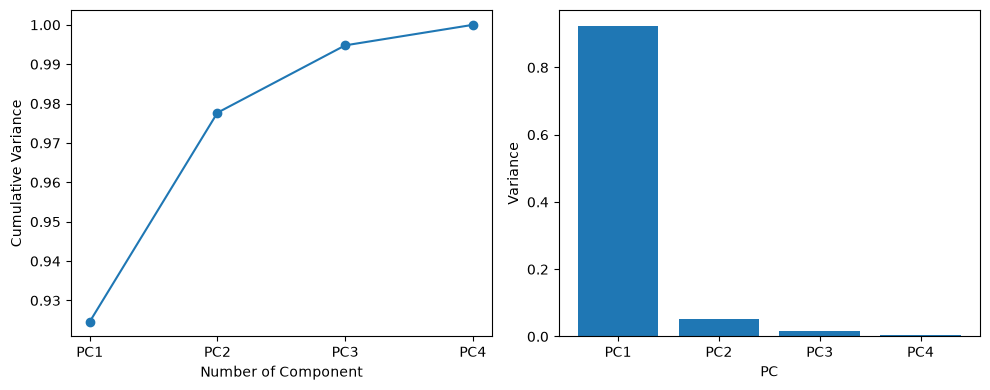

In [4]:
pca = PCA(n_components=4)
x_pca = pca.fit_transform(x)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

axs[0].set_xlabel("Number of Component")
axs[0].set_ylabel("Cumulative Variance")
axs[0].set_xticks(
    [0, 1, 2, 3],
    ["PC1", "PC2", "PC3", "PC4"]
)

axs[1].bar(
    ["PC1", "PC2", "PC3", "PC4"],
    pca.explained_variance_ratio_
)

axs[1].set_xlabel("PC")
axs[1].set_ylabel("Variance")

plt.tight_layout()
plt.show()